# Résultats du projet 1

Ce notebook relit les résultats produits par `src.evaluate` et `src.analyze`. Il ne relance aucune évaluation : le test a été utilisé une seule fois, après avoir figé le protocole (`results/protocole_fige.md`).

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
R = Path("../results")
pd.set_option("display.width", 160)
summary = pd.read_csv(R / "test_summary.csv", header=[0, 1], index_col=0)
(summary.xs("mean", axis=1, level=1).T * 1).round(4)

model,flat,hier,soft
acc_variant,0.6870,0.6965,0.6959
balanced_acc_variant,0.6871,0.6966,0.6959
acc_family,0.7979,0.8176,0.8074
acc_manufacturer,0.8637,0.8593,0.8733
top5_variant,0.8974,0.9069,0.9137
severity_mean_error,2.1591,2.0491,2.0581
severity_mean_all,0.6759,0.6220,0.6260
errors_same_family,0.3166,0.3610,0.3614
errors_same_manufacturer,0.2076,0.2288,0.2190
errors_other_manufacturer,0.4757,0.4102,0.4196


## Écart-type entre les 3 graines

In [2]:
summary.xs("std", axis=1, level=1).T.round(4)

model,flat,hier,soft
acc_variant,0.0015,0.0056,0.0035
balanced_acc_variant,0.0015,0.0057,0.0034
acc_family,0.0039,0.0022,0.0045
acc_manufacturer,0.0014,0.0011,0.0037
top5_variant,0.0030,0.0017,0.0012
severity_mean_error,0.0054,0.0082,0.0112
severity_mean_all,0.0020,0.0110,0.0103
errors_same_family,0.0020,0.0096,0.0081
errors_same_manufacturer,0.0089,0.0120,0.0078
errors_other_manufacturer,0.0071,0.0036,0.0052


## Différences entre modèles (bootstrap apparié, IC à 95 %)

In [3]:
pd.read_csv(R / "test_differences.csv").round(4)

,comparison,metric,diff,ci_low,ci_high,significant
0,hier - flat,acc_variant,0.0095,0.0023,0.0160,True
1,hier - flat,severity_mean_all,-0.0539,-0.0696,-0.0367,True
2,hier - flat,grave_error_rate,-0.0244,-0.0299,-0.0188,True
3,soft - flat,acc_variant,0.0089,0.0036,0.0145,True
4,soft - flat,severity_mean_all,-0.0499,-0.0643,-0.0358,True
5,soft - flat,grave_error_rate,-0.0213,-0.0266,-0.0159,True
6,soft - hier,acc_variant,-0.0006,-0.0077,0.0068,False
7,soft - hier,severity_mean_all,0.0040,-0.0129,0.0202,False
8,soft - hier,grave_error_rate,0.0031,-0.0026,0.0091,False


## Figures

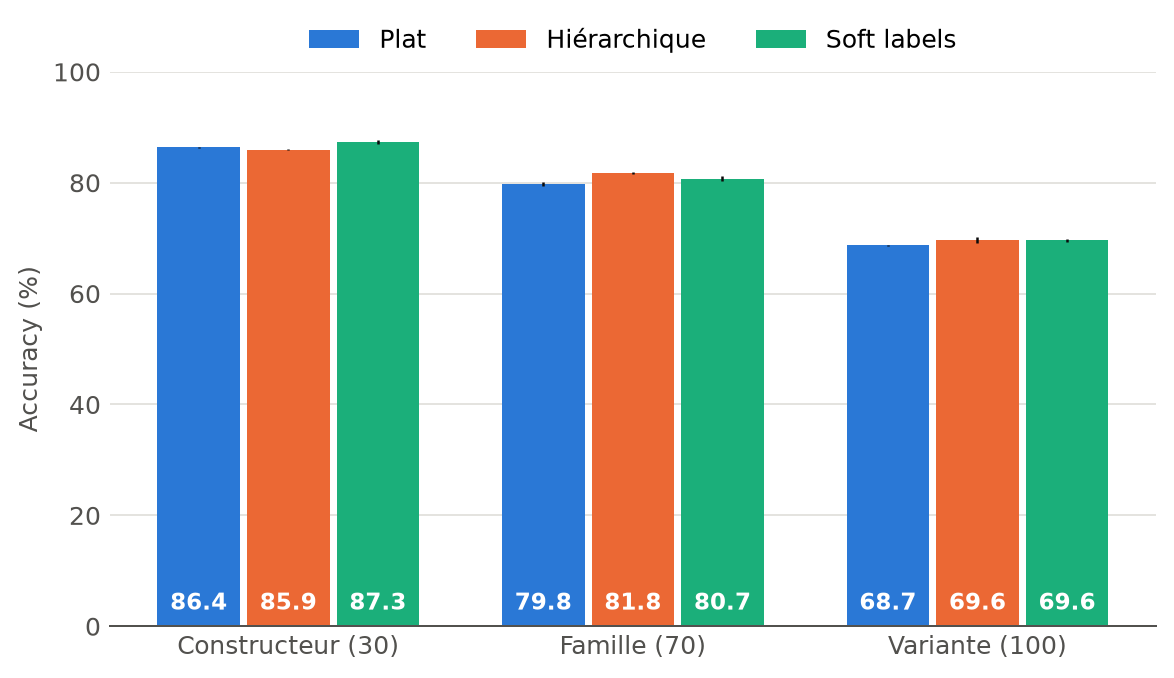

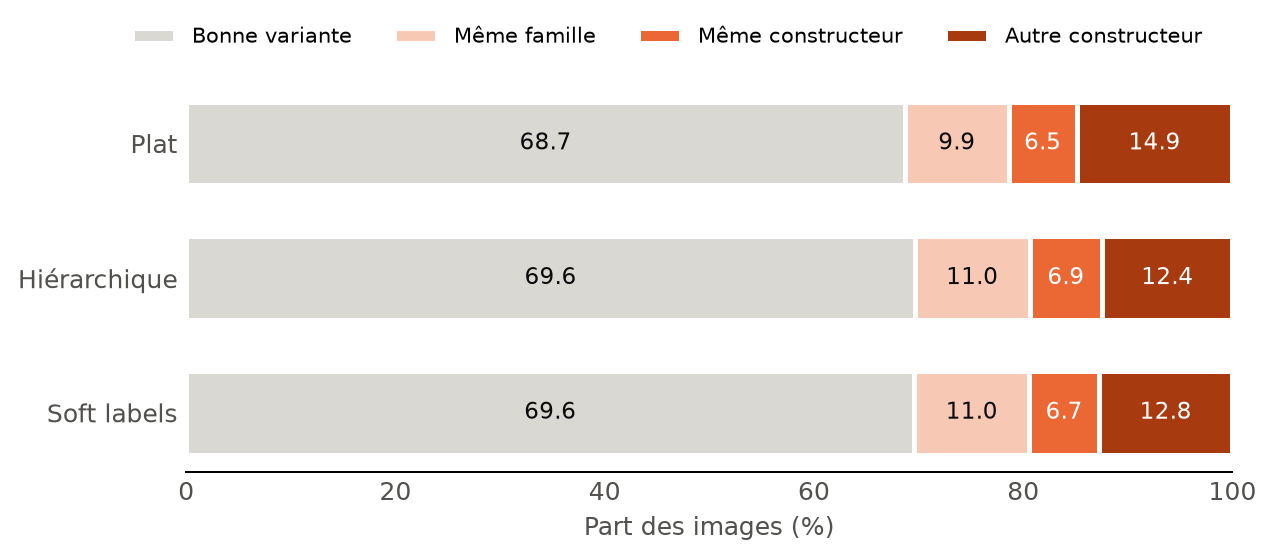

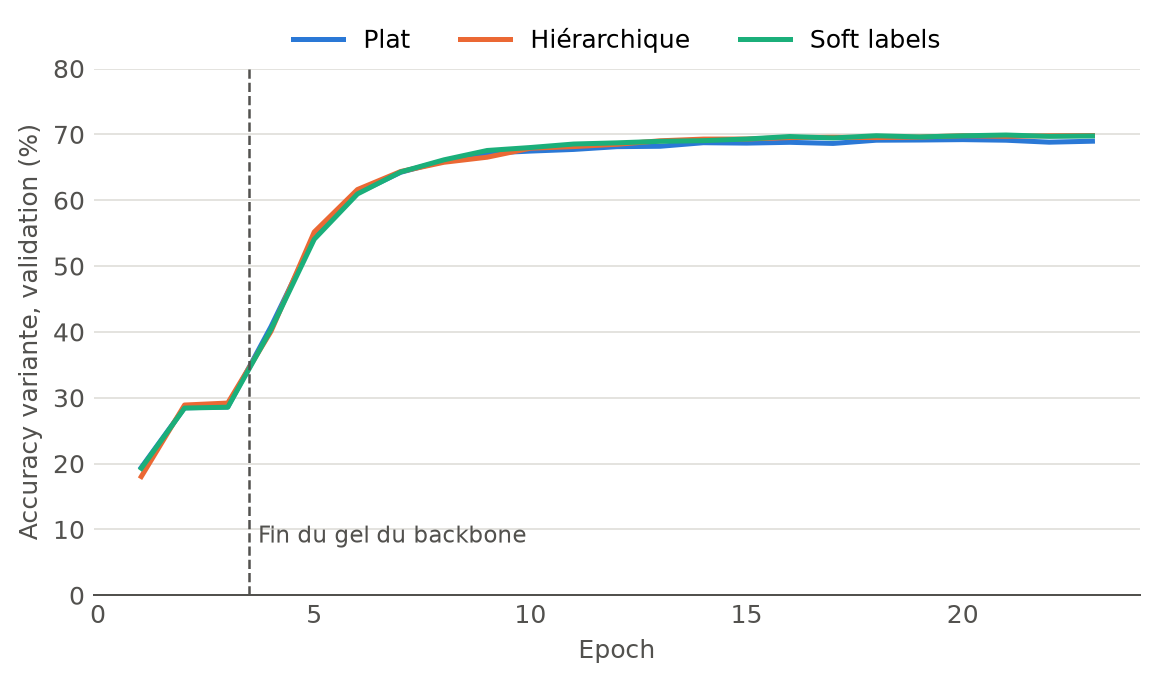

In [4]:
for f in ("test_niveaux", "test_gravite", "courbes_validation"):
    display(Image(R / "figures" / f"{f}.png", width=650))

## Confusions les plus fréquentes (soft labels, moyenne des 3 graines)

In [5]:
pd.read_csv(R / "test_confusions.csv")

,vraie,predite,images,support,hauteur
0,C-47,DC-3,15.3,33,2
1,E-190,E-195,14.0,34,1
2,MD-11,DC-10,11.7,33,2
3,DC-3,C-47,11.3,34,2
4,A340-200,A340-300,10.7,34,1
5,BAE 146-300,BAE 146-200,10.3,34,1
6,A330-300,A330-200,9.0,33,1
7,MD-90,MD-80,8.7,33,2
8,CRJ-700,CRJ-900,8.7,33,1
9,A320,A319,8.0,33,1


## Variantes les mieux et les moins bien reconnues

In [6]:
v = pd.read_csv(R / "test_per_variant.csv").round(3)
pd.concat([v.head(8), v.tail(8)])

,variante,accuracy,support
0,737-300,0.263,33.0
1,767-300,0.333,34.0
2,C-47,0.364,33.0
3,737-800,0.382,34.0
4,747-200,0.382,34.0
5,A320,0.384,33.0
6,747-100,0.394,33.0
7,757-200,0.402,34.0
92,Yak-42,0.929,33.0
93,DH-82,0.939,33.0


## Grad-CAM

Images de validation tirées au hasard, par groupe.

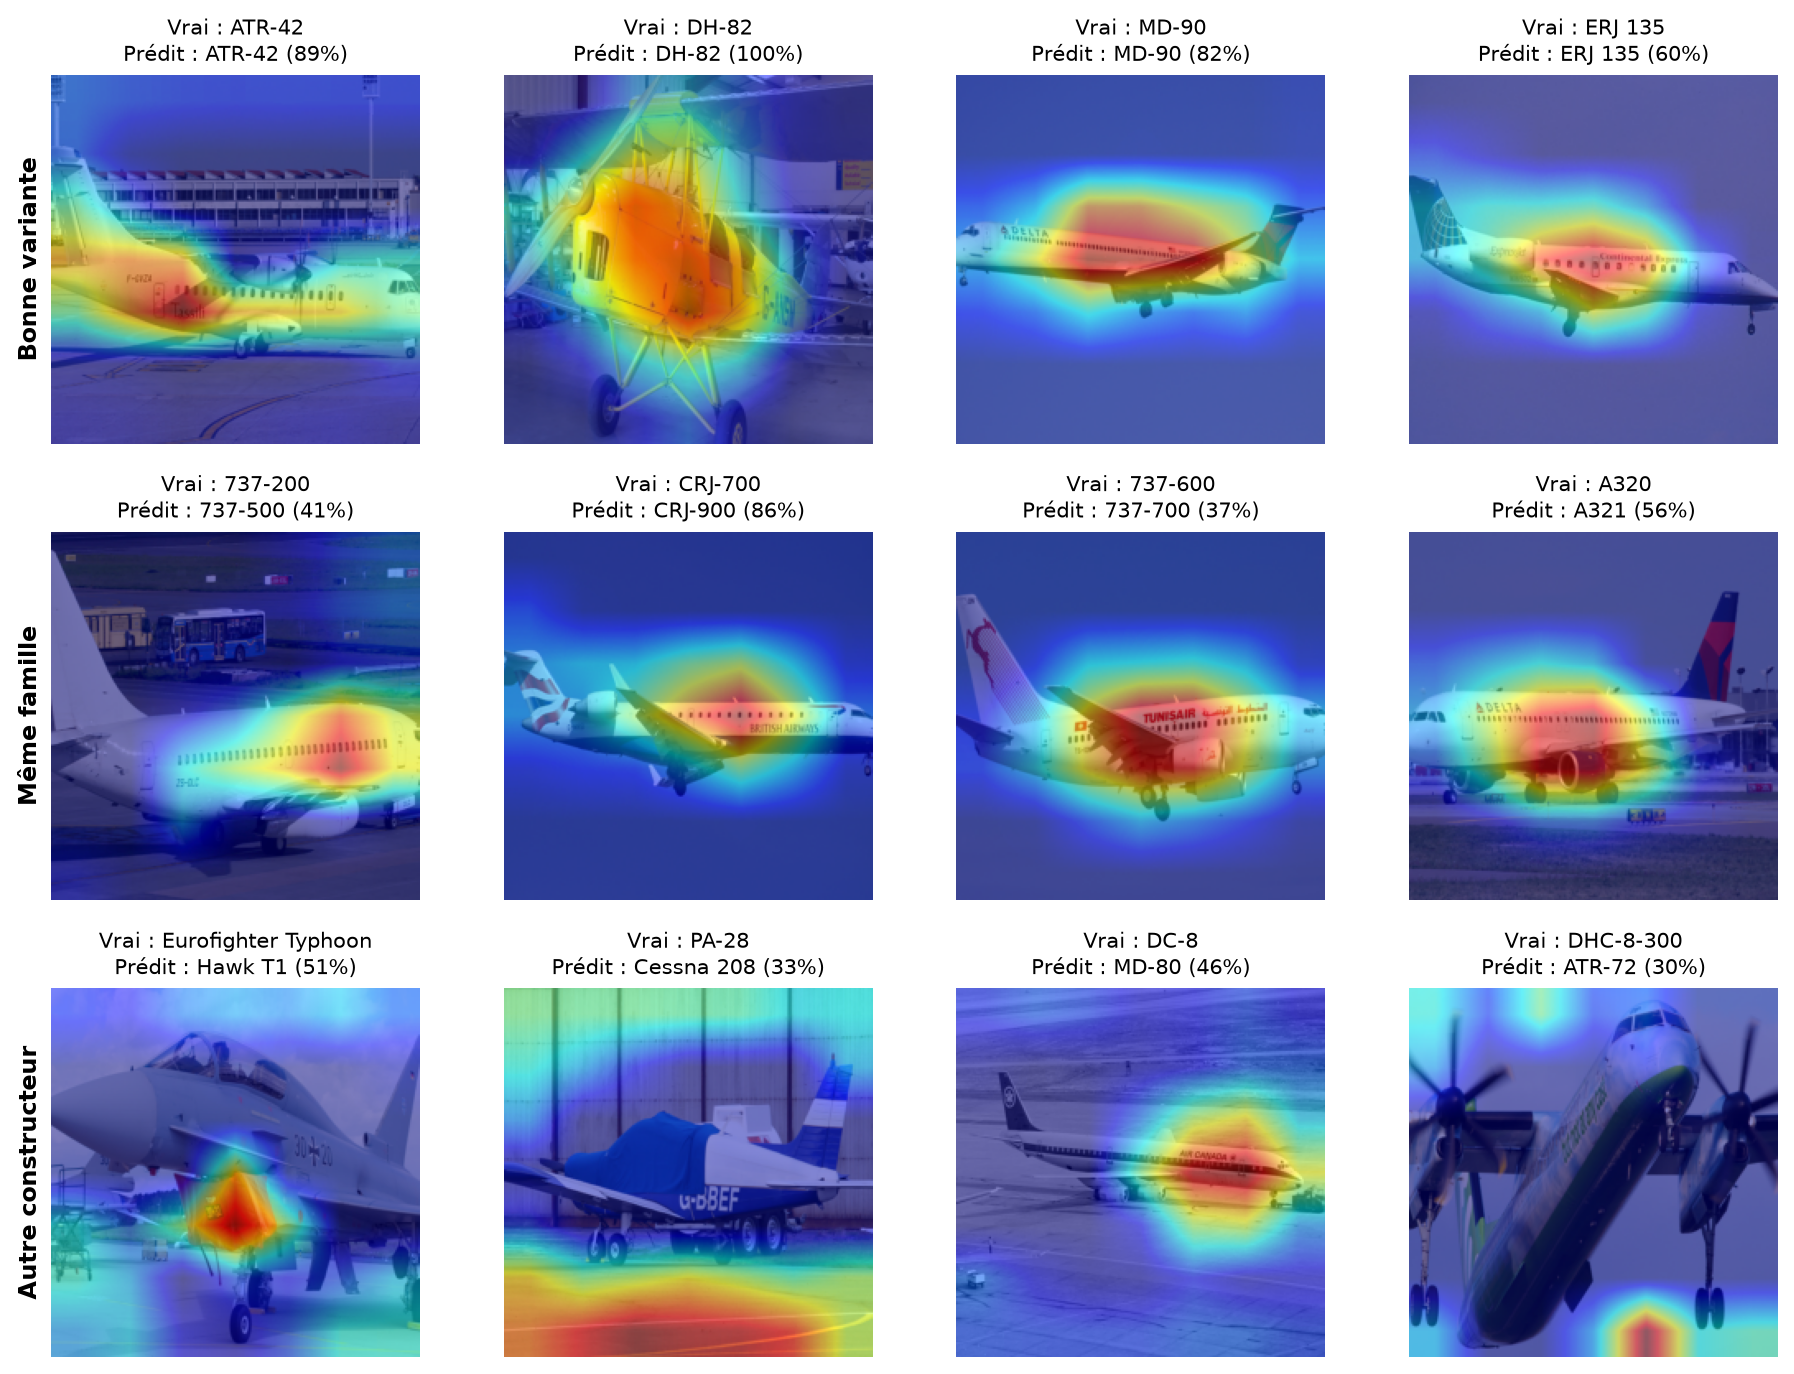

In [7]:
display(Image(R / "figures" / "gradcam_planche.png", width=800))